# assignment 2 code stuff
## part 2: networks
### make sure that we use same N = [1000, 5000, 10000] and same SEED = 42 for both docs

save all data as csv files and upload to git

In [2]:
#install packages
from scipy.integrate import odeint
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import fftpack
from scipy.optimize import minimize
import math
import ndlib
import networkx as nx
import ndlib.models.epidemics as ep
import os
import seaborn as sns

#set seed
SEED = 42
np.random.seed(SEED)

In [3]:
# #NO NEED TO RERUN
# #make networks of different types
# #several using the same params
# #rerun using N = 1000, 10000, 100.000?
# #how do P and M relate? how to make comparable er and sf networks?

# # Parameters
NETWORK_SIZES = [1000, 5000, 10000] #iterate across different ns
NUM_NETWORKS = 5 #5 per param constellation for the stochasticity
M = 10 #how many the new nodes in sf connects to
#SEED set at top of doc to 42

# output_dir = "networks"
# os.makedirs(output_dir, exist_ok=True)

# for N in NETWORK_SIZES:
#     # Match the expected average degree of ER to that of BA
#     P = (2 * M) / (N - 1)
#     print(f"\nGenerating networks with N={N}, P={P:.6f}, M={M}")
#     # Generate Erdős–Rényi networks
#     for i in range(NUM_NETWORKS):
#         g = nx.erdos_renyi_graph(
#             n=N,
#             p=P,
#             seed=SEED + i
#         )
#         filename = os.path.join(output_dir,f"erdos_renyi_N{N}_{i+1}.graphml")
#         nx.write_graphml(g, filename)
#         print(
#             f"Saved {filename}: "
#             f"N={g.number_of_nodes()}, "
#             f"L={g.number_of_edges()}, "
#             f"mean degree={2*g.number_of_edges()/N:.2f}"
#         )
#     # Generate scale-free Barabási–Albert networks
#     for i in range(NUM_NETWORKS):
#         g = nx.barabasi_albert_graph(
#             n=N,
#             m=M,
#             seed=SEED + 100 + i
#         )

#         filename = os.path.join(output_dir,f"scale_free_N{N}_{i+1}.graphml")
#         nx.write_graphml(g, filename)
#         print(
#             f"Saved {filename}: "
#             f"N={g.number_of_nodes()}, "
#             f"L={g.number_of_edges()}, "
#             f"mean degree={2*g.number_of_edges()/N:.2f}"
#         )

# print("\nAll networks have been generated and saved.")



In [4]:
# #NO NEED TO RERUN
# #get degree clustering and centrality stats per network and summary
# # folders
input_dir = "networks"
output_dir = "network_metrics"
os.makedirs(output_dir, exist_ok=True)

# # Experiment parameters
# NETWORK_SIZES = [1000, 5000, 10000]
# NUM_NETWORKS = 5
# NETWORK_TYPES = ["erdos_renyi", "scale_free"]

# # Store summary statistics for all networks
# summary = []

# for N in NETWORK_SIZES:
#     for network_type in NETWORK_TYPES:
#         for i in range(1, NUM_NETWORKS + 1):

#             # Match the naming convention used when saving networks
#             filename = f"{network_type}_N{N}_{i}.graphml"
#             filepath = os.path.join(input_dir, filename)

#             if not os.path.exists(filepath):
#                 print(f"File not found, skipping: {filepath}")
#                 continue

#             # Load network
#             G = nx.read_graphml(filepath)

#             # Network-level properties
#             n_nodes = G.number_of_nodes()
#             n_edges = G.number_of_edges()
#             density = nx.density(G)

#             # Node-level metrics
#             degree = dict(G.degree())
#             degree_centrality = nx.degree_centrality(G)
#             clustering = nx.clustering(G)

#             # Create table with one row per node
#             #centrality and clustering are already normalized in nx
#             df = pd.DataFrame({
#                 "node": list(G.nodes()),
#                 "degree": [degree[n] for n in G.nodes()],
#                 "degree_centrality": [
#                     degree_centrality[n] for n in G.nodes()
#                 ],
#                 "clustering_coefficient": [
#                     clustering[n] for n in G.nodes()
#                 ]
#             })

#             # Save node-level metrics
#             output_filename = filename.replace(".graphml", "_metrics.csv")
#             output_path = os.path.join(output_dir, output_filename)
#             df.to_csv(output_path, index=False)

#             # Network-level summary
#             summary.append({
#                 "network_type": network_type,
#                 "N": n_nodes,
#                 "replicate": i,
#                 "L": n_edges,
#                 "density": density,
#                 "mean_degree": df["degree"].mean(),
#                 "mean_degree_centrality":
#                     df["degree_centrality"].mean(),
#                 "mean_clustering":
#                     df["clustering_coefficient"].mean()
#             })

#             print(
#                 f"Processed {filename}: "
#                 f"N={n_nodes}, L={n_edges}, "
#                 f"mean degree centrality="
#                 f"{df['degree_centrality'].mean():.5f}, "
#                 f"mean clustering="
#                 f"{df['clustering_coefficient'].mean():.5f}"
#             )

# # Save summary of all networks
# summary_df = pd.DataFrame(summary)
# summary_path = os.path.join(
#     output_dir, "network_summary.csv"
# )
# summary_df.to_csv(summary_path, index=False)

# print("\nAll network metrics have been calculated.")
# print(f"Summary saved to: {summary_path}")


       N network_type mean_degree_centrality           mean_clustering  \
                                        mean       std            mean   
0   1000           ER               0.019869  0.000139        0.019746   
1   1000           SF               0.019820  0.000000        0.061348   
2   5000           ER               0.003992  0.000029        0.003944   
3   5000           SF               0.003993  0.000000        0.018790   
4  10000           ER               0.002001  0.000005        0.001949   
5  10000           SF               0.001998  0.000000        0.010910   

             
        std  
0  0.000722  
1  0.001422  
2  0.000138  
3  0.000790  
4  0.000060  
5  0.000406  


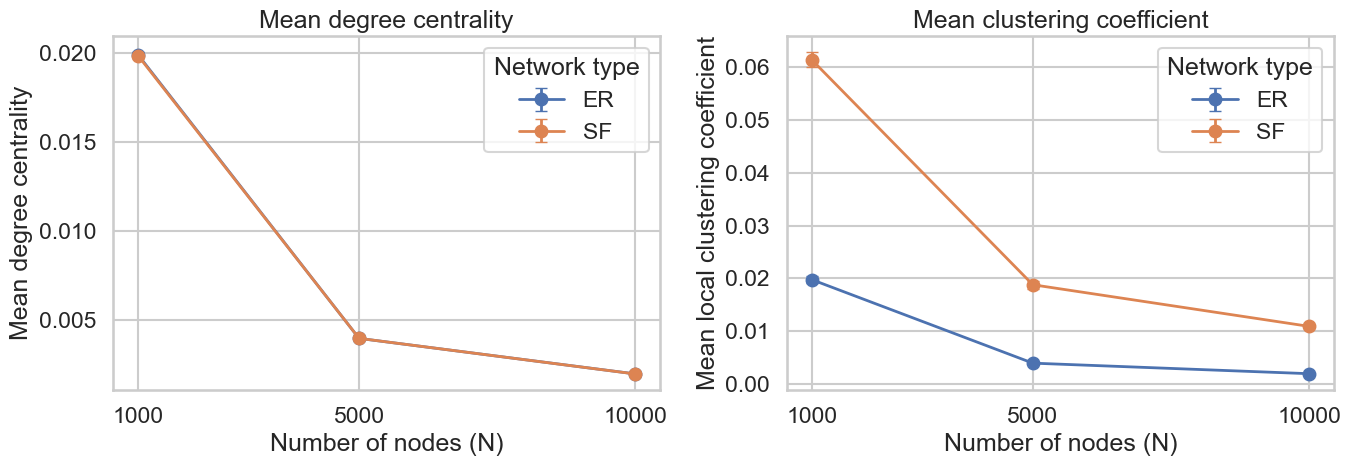

In [5]:
#plot stats comparing er and sf and effect of n

# Load network-level summary
input_file = os.path.join("network_metrics", "network_summary.csv")
output_dir = "network_plots"
os.makedirs(output_dir, exist_ok=True)

summary = pd.read_csv(input_file)

# Friendly labels
summary["network_type"] = summary["network_type"].map({
    "erdos_renyi": "ER",
    "scale_free": "SF"
})

# Average over repetitions for each network type and size
metrics = ["mean_degree_centrality","mean_clustering"]

averaged = (
    summary.groupby(["N", "network_type"])[metrics]
    .agg(["mean", "std"])
    .reset_index()
)

print(averaged)

sns.set_theme(style="whitegrid", context="talk")

# Plot mean degree centrality and clustering
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for network_type, group in averaged.groupby("network_type"):
    # Extract columns from the multi-index table
    x = group["N"].to_numpy()

    centrality_mean = group["mean_degree_centrality"]["mean"].to_numpy()
    centrality_std = group["mean_degree_centrality"]["std"].fillna(0).to_numpy()

    clustering_mean = group["mean_clustering"]["mean"].to_numpy()
    clustering_std = group["mean_clustering"]["std"].fillna(0).to_numpy()

    axes[0].errorbar(
        x, centrality_mean, yerr=centrality_std,
        marker="o", capsize=4, linewidth=2,
        label=network_type
    )

    axes[1].errorbar(
        x, clustering_mean, yerr=clustering_std,
        marker="o", capsize=4, linewidth=2,
        label=network_type
    )

# Degree centrality plot
axes[0].set_title("Mean degree centrality")
axes[0].set_xlabel("Number of nodes (N)")
axes[0].set_ylabel("Mean degree centrality")
axes[0].set_xticks([1000, 5000, 10000])
axes[0].ticklabel_format(axis="x", style="plain")
axes[0].legend(title="Network type")

# Clustering plot
axes[1].set_title("Mean clustering coefficient")
axes[1].set_xlabel("Number of nodes (N)")
axes[1].set_ylabel("Mean local clustering coefficient")
axes[1].set_xticks([1000, 5000, 10000])
axes[1].ticklabel_format(axis="x", style="plain")
axes[1].legend(title="Network type")

plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "ER_vs_SF_by_network_size.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## implement sir on ER and SF models

In [6]:
#apply simple sir to network
#we use already finished sf models i assume
#fixed fraction of initial infected = 5 percent
### to do: rerun gillespie etc above so the Ns match all through the doc
import networkx as nx
import ndlib.models.CompositeModel as gc
import ndlib.models.compartments as ns
import ndlib.models.ModelConfig as mc
import ndlib.models.compartments as es

# Load an existing network; do not generate a new one
g = nx.read_graphml("networks/erdos_renyi_N1000_1.graphml")

beta = 0.8
gamma = 0.6

# Create model
model = gc.CompositeModel(g)

# Define statuses
model.add_status("Susceptible")
model.add_status("Infected")
model.add_status("Recovered")

# Infection rule: S -> I if at least one neighbor is I
#infected with probability beta, is this how beta works here?? 
###should it be in relation to each edge, so more likely if more neighbors?
# c1 = ns.NodeStochastic(
#     beta,
#     triggering_status="Infected"
# )
# model.add_rule("Susceptible", "Infected", c1)

###better:
# Infection: S -> I, with probability beta per eligible edge
c1 = es.EdgeStochastic(
    beta,
    triggering_status="Infected"
)
model.add_rule("Susceptible", "Infected", c1)

# Recovery: I -> R, with probability gamma
c2 = ns.NodeStochastic(gamma)
model.add_rule("Infected", "Recovered", c2)

# Recovery rule: I -> R with probability gamma
#so recovery rate gamma
c2 = ns.NodeStochastic(gamma)
model.add_rule("Infected", "Recovered", c2)

# Initialize 5% of nodes as infected
###we can change this to 5 nodes but this is comparable to other stochastic models....
config = mc.Configuration()
config.add_model_parameter("fraction_infected", 0.05)
model.set_initial_status(config)

# Run simulation
iterations = model.iteration_bunch(100)

# Extract results
trends = model.build_trends(iterations)

print(trends)



[{'trends': {'node_count': {0: [950, 416, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 1: [50, 539, 491, 76, 14, 5, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 2: [0, 45, 509, 924, 986, 995, 999, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 100

In [7]:
#plot SIR dynamics
%matplotlib inline

from ndlib.viz.mpl.DiffusionTrend import DiffusionTrend

viz = DiffusionTrend(model, trends)
viz.plot()

no display found. Using non-interactive Agg backend
no display found. Using non-interactive Agg backend
no display found. Using non-interactive Agg backend


c:\Users\anton\anaconda3\Lib\site-packages\ndlib\viz\mpl\DiffusionViz.py:100: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [8]:
# #repeat over all networks
# ###important: how does the stochasticity work here? related to the seed at all? should we rerun 5 times with different seeds per network??

# import os
# import glob
# import itertools

# import networkx as nx
# import pandas as pd

# import ndlib.models.CompositeModel as gc
# import ndlib.models.compartments as ns
# import ndlib.models.compartments as es
# import ndlib.models.ModelConfig as mc


# # -----------------------------
# # Simulation parameters
# # -----------------------------
# network_files = sorted(glob.glob("networks/*.graphml"))

# betas = [0.8, 0.6, 0.4]
# gammas = [0.6, 0.4]

# fraction_infected = 0.05
# n_iterations = 100

# # Output folder
# output_folder = "sir_results"
# os.makedirs(output_folder, exist_ok=True)

# time_series_rows = []
# summary_rows = []


# # -----------------------------
# # Run simulations
# # -----------------------------
# for network_file in network_files:

#     # Load existing network
#     g = nx.read_graphml(network_file)

#     network_name = os.path.basename(network_file)
#     N = g.number_of_nodes()

#     print(f"\nNetwork: {network_name} | N = {N}")

#     for beta, gamma in itertools.product(betas, gammas):

#         print(f"  beta = {beta}, gamma = {gamma}")

#         # Create a fresh model for each simulation
#         model = gc.CompositeModel(g)

#         # Define statuses
#         model.add_status("Susceptible")
#         model.add_status("Infected")
#         model.add_status("Recovered")

#         # Edge-based infection rule
#         infection_rule = es.EdgeStochastic(
#             beta,
#             triggering_status="Infected"
#         )
#         model.add_rule(
#             "Susceptible", "Infected", infection_rule
#         )

#         # Node-based recovery rule
#         recovery_rule = ns.NodeStochastic(gamma)
#         model.add_rule(
#             "Infected", "Recovered", recovery_rule
#         )

#         # Initialize 5% of nodes as infected
#         config = mc.Configuration()
#         config.add_model_parameter(
#             "fraction_infected", fraction_infected
#         )
#         model.set_initial_status(config)

#         # Run simulation
#         iterations = model.iteration_bunch(n_iterations)

#         # Extract status counts
#         status_ids = {
#             "Susceptible": 0,
#             "Infected": 1,
#             "Recovered": 2
#         }
#         run_rows = []

#         for iteration in iterations:

#             counts = iteration["node_count"]

#             def get_count(status_name):
#                 status_id = status_ids[status_name]
#                 return counts.get(
#                     status_id,
#                     counts.get(status_name, 0)
#                 )

#             S = get_count("Susceptible")
#             I = get_count("Infected")
#             R = get_count("Recovered")

#             row = {
#                 "network": network_name,
#                 "N": N,
#                 "beta": beta,
#                 "gamma": gamma,
#                 "iteration": iteration["iteration"],
#                 "S": S,
#                 "I": I,
#                 "R": R,
#                 "infected_fraction": I / N,
#                 "recovered_fraction": R / N
#             }

#             run_rows.append(row)
#             time_series_rows.append(row)

#         # Summarize this run
#         if run_rows:
#             peak_row = max(run_rows, key=lambda x: x["I"])
#             final_row = run_rows[-1]

#             summary_rows.append({
#                 "network": network_name,
#                 "N": N,
#                 "beta": beta,
#                 "gamma": gamma,
#                 "peak_infected": peak_row["I"],
#                 "peak_infected_fraction":
#                     peak_row["I"] / N,
#                 "peak_iteration": peak_row["iteration"],
#                 "final_S": final_row["S"],
#                 "final_I": final_row["I"],
#                 "final_R": final_row["R"],
#                 "final_recovered_fraction":
#                     final_row["R"] / N
#             })


# # -----------------------------
# # Save results
# # -----------------------------
# time_series_df = pd.DataFrame(time_series_rows)
# summary_df = pd.DataFrame(summary_rows)

# time_series_path = os.path.join(
#     output_folder, "sir_time_series.csv"
# )
# summary_path = os.path.join(
#     output_folder, "sir_summary.csv"
# )

# time_series_df.to_csv(time_series_path, index=False)
# summary_df.to_csv(summary_path, index=False)

# print("\nAll simulations completed!")
# print(f"Networks processed: {len(network_files)}")
# print(f"Simulations run: {len(summary_df)}")
# print(f"Time series saved to: {time_series_path}")
# print(f"Summary saved to: {summary_path}")

# print("\nSummary of results:")
# print(summary_df)


In [9]:
import pandas as pd
import networkx as nx

# Load the weighted adjacency matrix
A = pd.read_csv("transmission_network.csv", index_col=0, sep = ";")

# Convert to binary: existing edges = 1, no edge = 0
A_binary = (A != 0).astype(int)

# Create an unweighted NetworkX graph

A.columns = A.columns.astype(int)

G = nx.from_pandas_adjacency(A)



# # Save in the same format as your other networks
nx.write_graphml(G, "networks/my_network.graphml")

# # Check the result
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Weighted edges:", nx.is_weighted(G))

print("Density:", nx.density(G))
print("Average degree:", sum(dict(G.degree()).values()) / G.number_of_nodes())
print("Connected components:", nx.number_connected_components(G))

Nodes: 374
Edges: 1265
Weighted edges: True
Density: 0.018135940703359093
Average degree: 6.764705882352941
Connected components: 19


c:\Users\anton\anaconda3\Lib\site-packages\ndlib\models\DiffusionModel.py:173: UserWarning: Initial infection missing: a random sample of 5% of graph nodes will be set as infected
  warnings.warn(


Original total nodes: 374
Isolated nodes (excluded from simulation): 16
Simulation nodes: 358
Initially infected nodes: [1725, 1640, 1517, 1671, 1813]
[{'trends': {'node_count': {0: [341, 285, 124, 33, 12, 8, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7], 1: [17, 67, 183, 164, 77, 33, 12, 5, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 2: [0, 6, 51, 161, 269, 317, 339, 346, 349, 350, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 

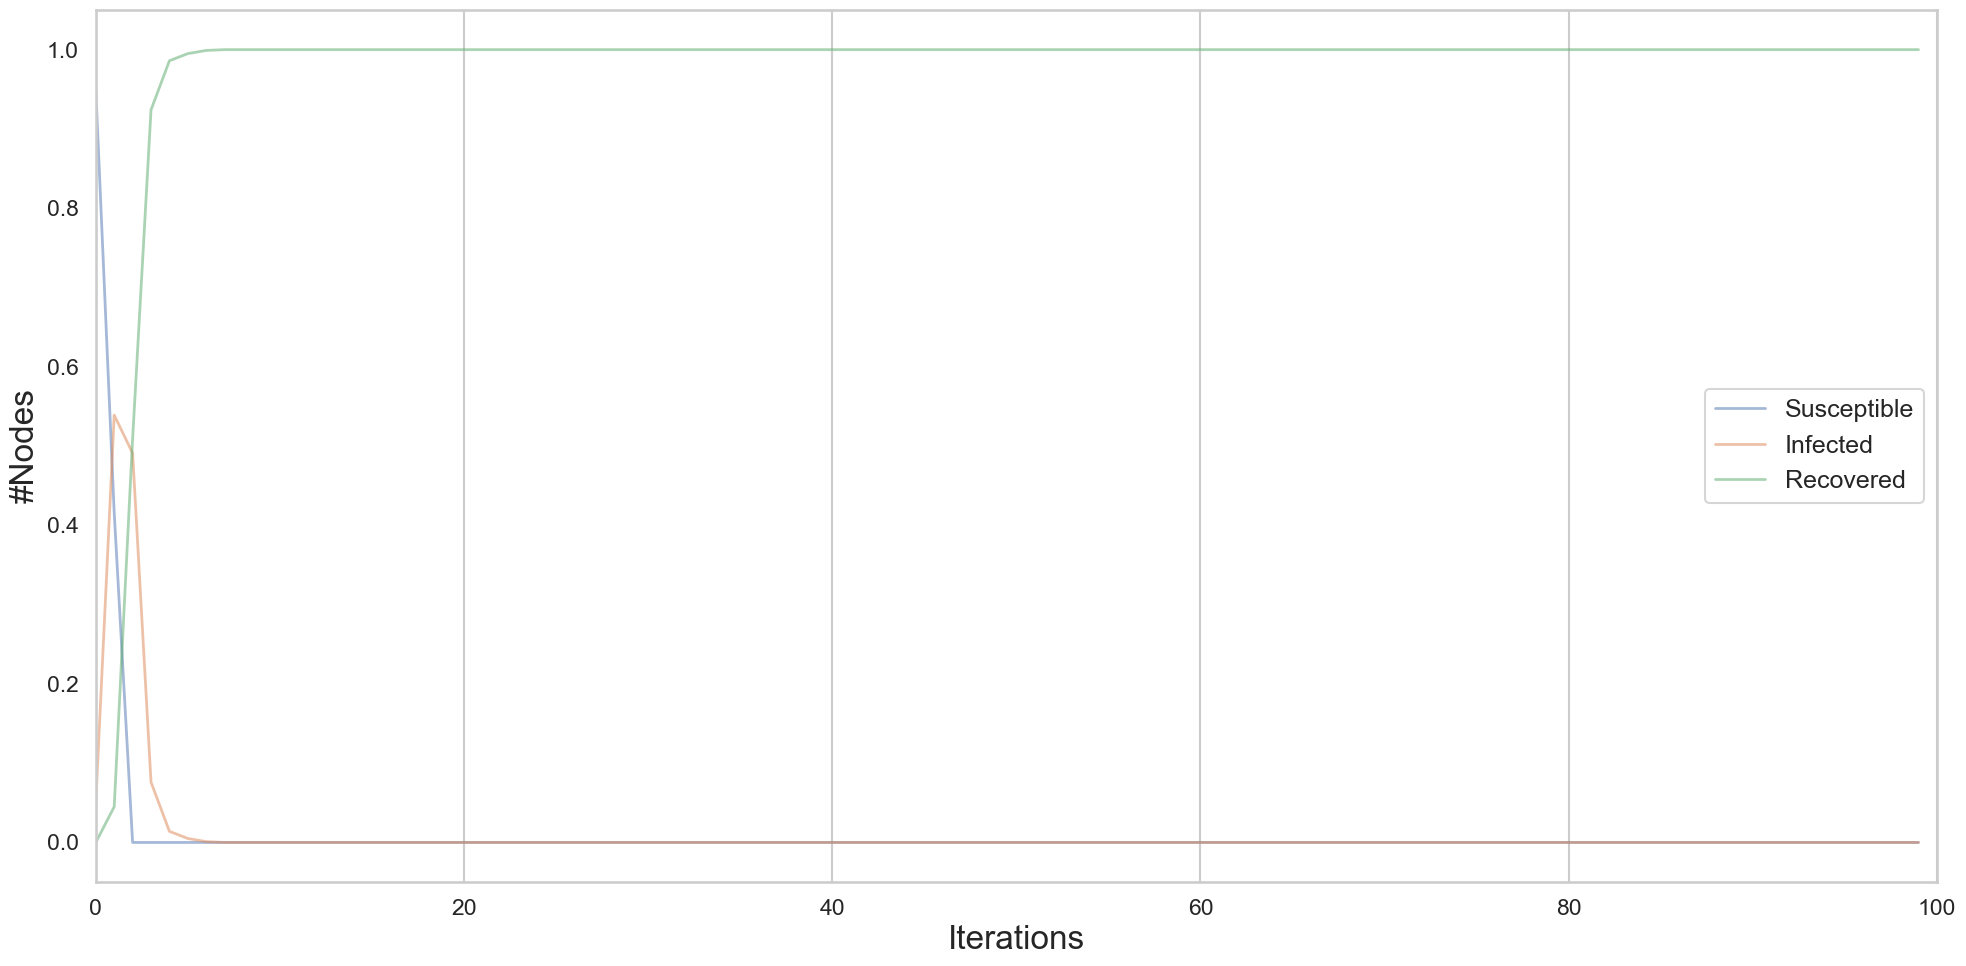

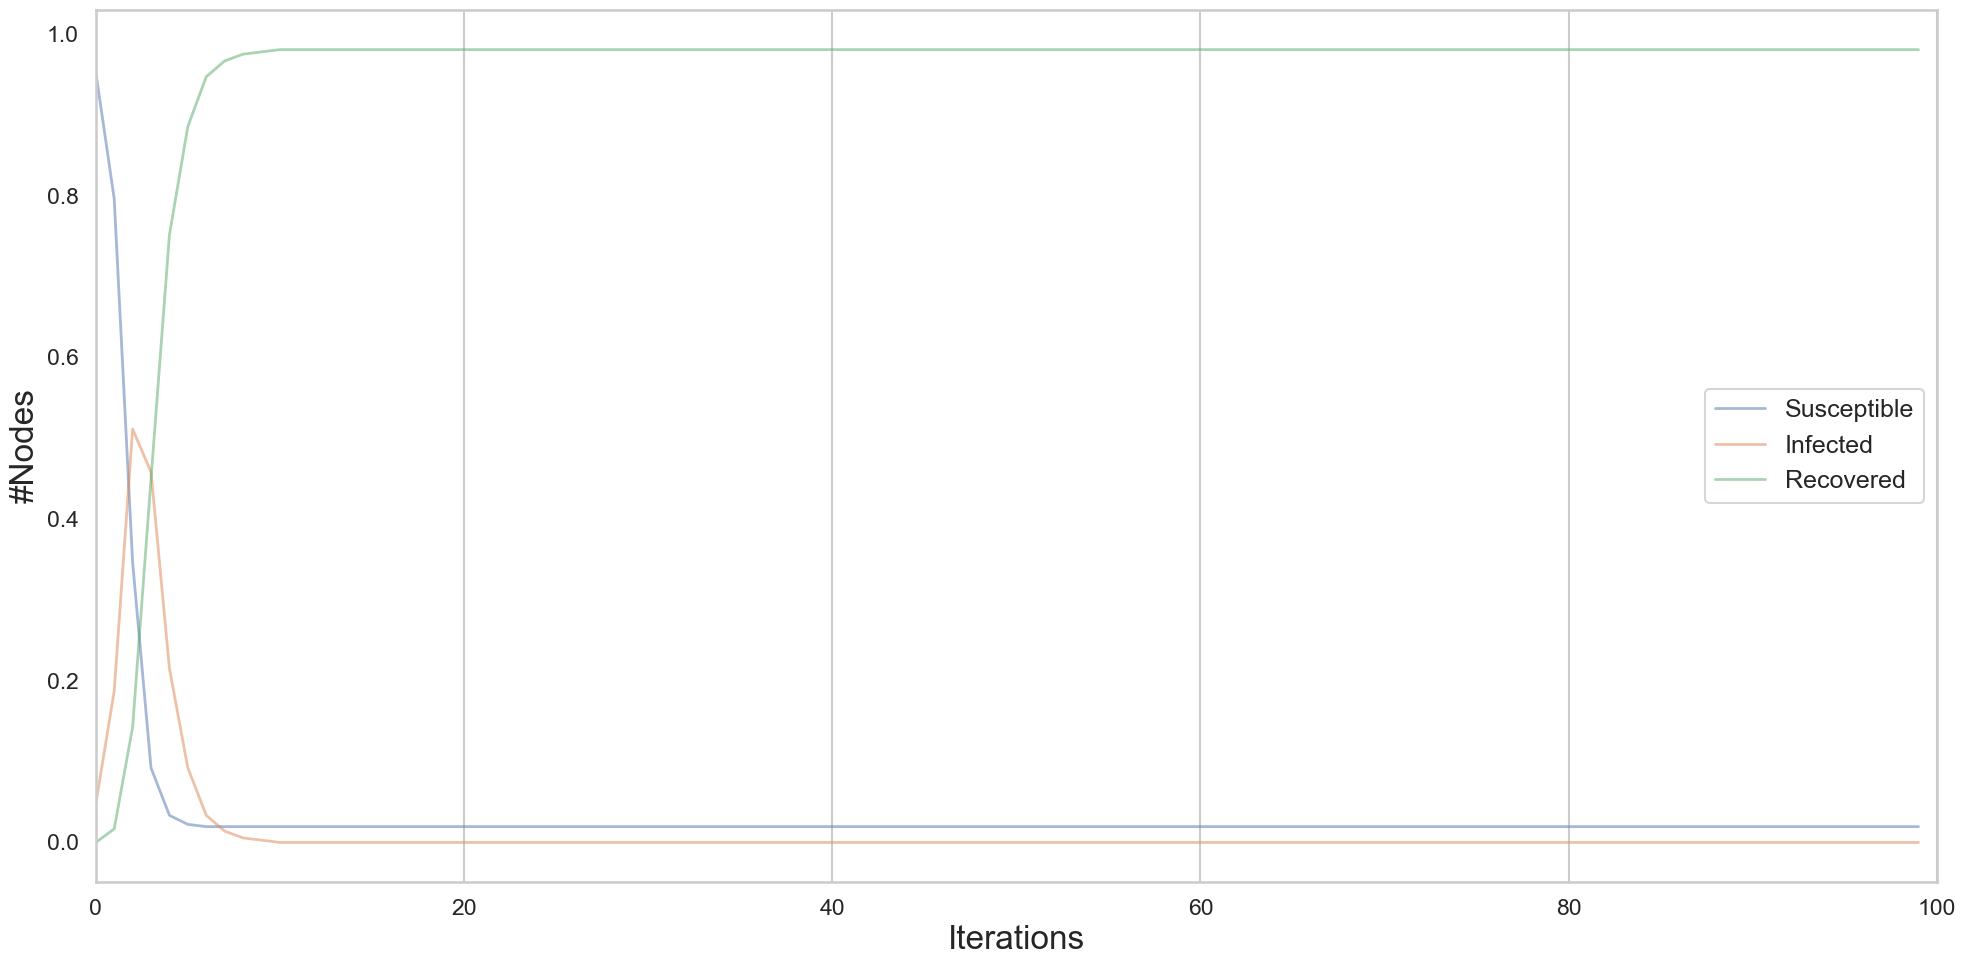

In [13]:
#run sir on network
#randomly infect exactly 5 at beginning
#important: rule for infection adapted since we have 16 isolated nodes and cant take them out
###stupid patch: remove those for sim
###any better ideas?
# Keep your existing imports; remove the BaseCompartment import
import random

# Identify isolated nodes
isolated_nodes = set(nx.isolates(G))

# Create a copy of the graph for simulation
G_sim = G.copy()

# Remove isolated nodes only from the simulation graph
G_sim.remove_nodes_from(isolated_nodes)

# Create the model on the simulation graph
model = gc.CompositeModel(G_sim)

# Define statuses
model.add_status("Susceptible")
model.add_status("Infected")
model.add_status("Recovered")

# Original infection and recovery rules
c1 = es.EdgeStochastic(beta, triggering_status="Infected")
model.add_rule("Susceptible", "Infected", c1)

c2 = ns.NodeStochastic(gamma)
model.add_rule("Infected", "Recovered", c2)

# Infect exactly 5 non-isolated nodes
infected_nodes = random.sample(list(G_sim.nodes()), 5)

config = mc.Configuration()

for node in G_sim.nodes():
    config.add_node_configuration(
        "status", node,
        1 if node in infected_nodes else 0
    )

model.set_initial_status(config)

# Run simulation
iterations = model.iteration_bunch(100)
trends = model.build_trends(iterations)

print("Original total nodes:", G.number_of_nodes())
print("Isolated nodes (excluded from simulation):", len(isolated_nodes))
print("Simulation nodes:", G_sim.number_of_nodes())
print("Initially infected nodes:", infected_nodes)
print(trends)
#plot SIR dynamics
%matplotlib inline

from ndlib.viz.mpl.DiffusionTrend import DiffusionTrend

viz = DiffusionTrend(model, trends)
viz.plot()

In [30]:
### attempt at a patch so i dont have to delete the isolate nodes...doesnt work
# original_execute = es.EdgeStochastic.execute

# def safe_execute(self, node, graph, status, status_map, params,
#                  *args, **kwargs):

#     # Your network is undirected
#     neighbors = list(graph.neighbors(node))

#     # Avoid division by zero for isolated nodes
#     if len(neighbors) == 0:
#         return False

#     # Keep NDlib's original behavior for connected nodes
#     return original_execute(
#         self, node, graph, status, status_map, params,
#         *args, **kwargs
#     )

# es.EdgeStochastic.execute = safe_execute

[{'trends': {'node_count': {0: [341, 258, 83, 24, 14, 14, 13, 13, 13, 13, 12, 12, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 10, 10, 10, 10, 10, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 7, 7, 7, 7, 7, 7, 6, 6, 6, 6, 6, 6, 6, 5, 5], 1: [17, 87, 206, 137, 71, 37, 13, 5, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 2: [0, 13, 69, 197, 273, 307, 332, 340, 344, 344, 345, 346, 347, 347, 347, 347, 347, 347, 347, 347, 347, 347, 347, 347, 347, 347, 347, 347, 348, 348, 348, 348, 348, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349, 349

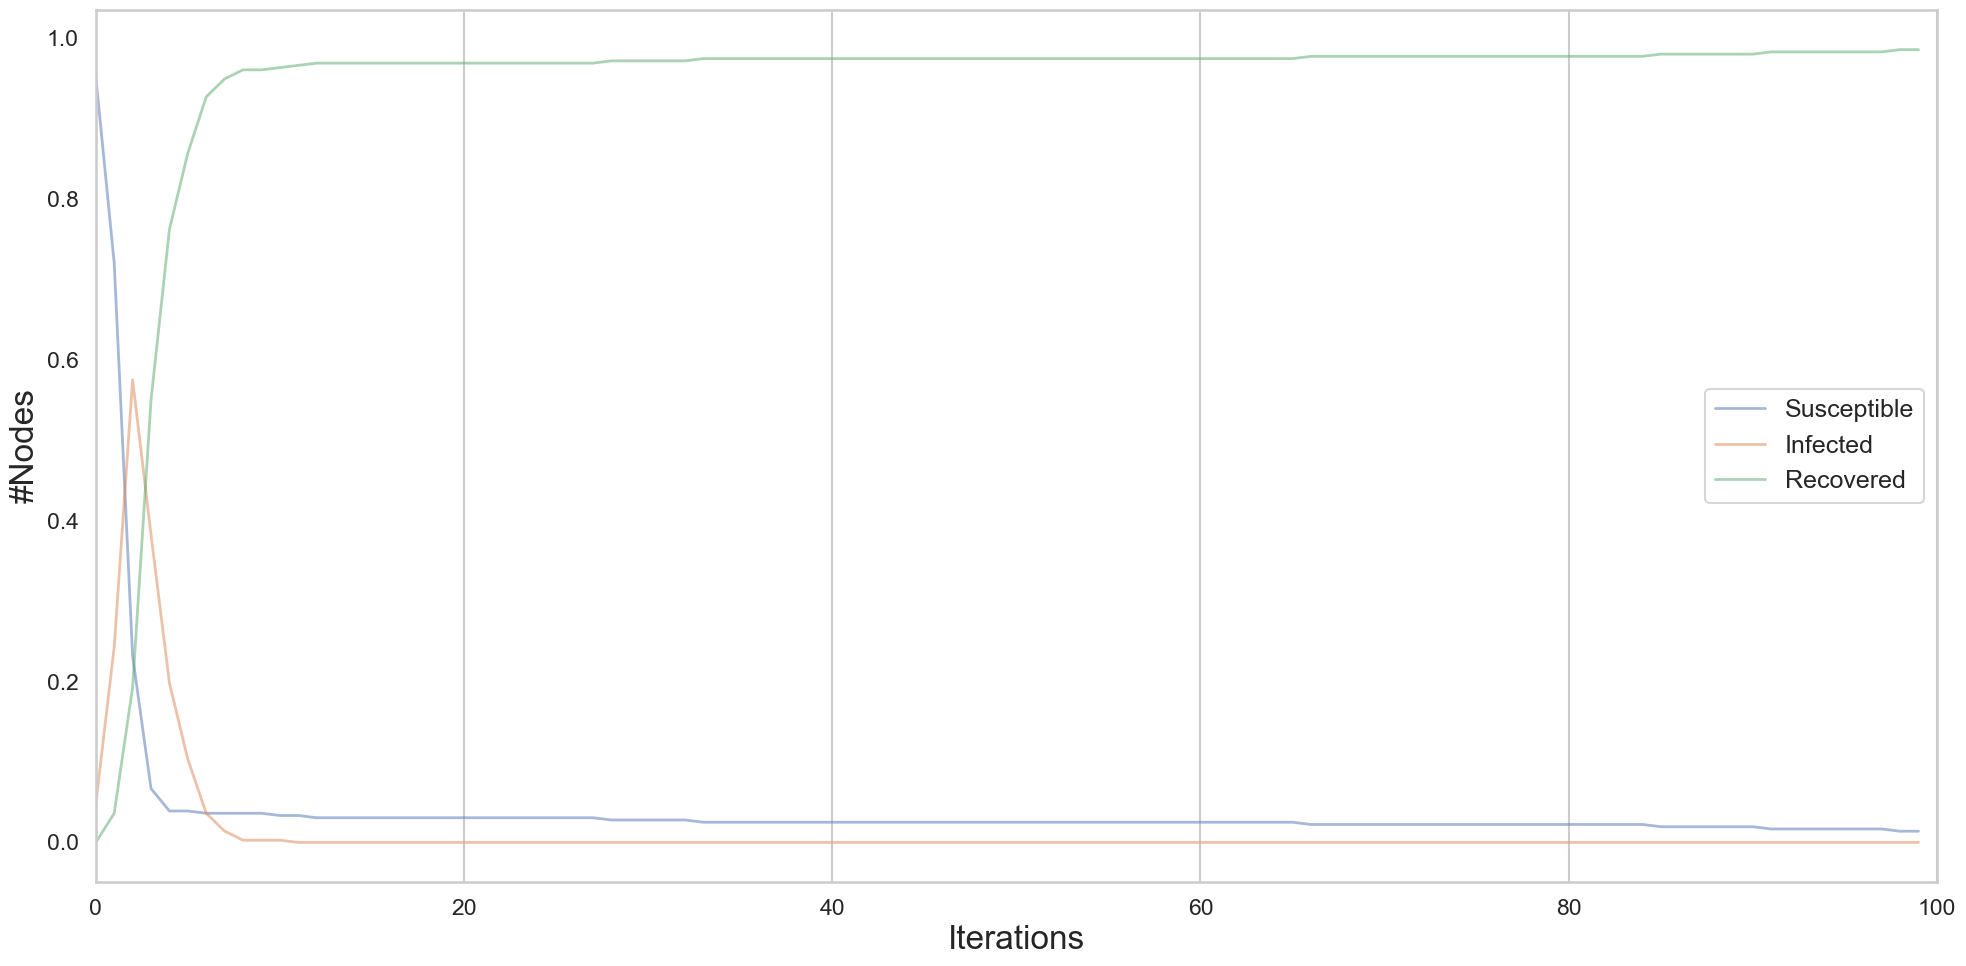

In [ ]:
# run baseline: randomly assign vaccination
#start with 1 vacc per timestep, then 5 then 10
#vaccination makes k per timestep go s->r
#careful! we only know status if we test so if we distribute randomly we get a certain numberr of i and r also, so no effect

import random
vacc_number = 5 # vaccinations per timestep

# Identify isolated nodes
isolated_nodes = set(nx.isolates(G))

# Create a copy of the graph for simulation
G_sim = G.copy()

# Remove isolated nodes only from the simulation graph
G_sim.remove_nodes_from(isolated_nodes)

# Create the model on the simulation graph
model = gc.CompositeModel(G_sim)

# Define statuses
model.add_status("Susceptible")
model.add_status("Infected")
model.add_status("Recovered")

# Original infection and recovery rules
c1 = es.EdgeStochastic(beta, triggering_status="Infected")
model.add_rule("Susceptible", "Infected", c1)

c2 = ns.NodeStochastic(gamma)
model.add_rule("Infected", "Recovered", c2)

# Infect exactly 5 non-isolated nodes
infected_nodes = random.sample(list(G_sim.nodes()), 5)

config = mc.Configuration()

for node in G_sim.nodes():
    config.add_node_configuration(
        "status", node,
        1 if node in infected_nodes else 0
    )

model.set_initial_status(config)

# Run simulation with a random intervention at each timestep
iterations = []

for t in range(100):
    # Advance the SIR model by one timestep
    iteration = model.iteration()
    iterations.append(iteration)

    # Randomly select 5 nodes at this timestep
    selected_nodes = random.sample(list(G_sim.nodes()), vacc_number) 

    # Change selected susceptible nodes to Recovered
    for node in selected_nodes:
        if model.status[node] == 0:  # Susceptible
            model.status[node] = 2  # Recovered
            #if the node is not sus at this timepoint, the update does nothing so we "waste" a vaccination

    # Record the updated statuses for the next timestep
    # Note: model.status is updated directly here

# Build trends
trends = model.build_trends(iterations)
print(trends)


print("Original total nodes:", G.number_of_nodes())
print("Isolated nodes (excluded from simulation):", len(isolated_nodes))
print("Simulation nodes:", G_sim.number_of_nodes())
print("Initially infected nodes:", infected_nodes)
print(trends)
#plot SIR dynamics
%matplotlib inline

from ndlib.viz.mpl.DiffusionTrend import DiffusionTrend

viz = DiffusionTrend(model, trends)
viz.plot()
###to do: iterate this 10 times

c:\Users\anton\anaconda3\Lib\site-packages\ndlib\models\DiffusionModel.py:173: UserWarning: Initial infection missing: a random sample of 5% of graph nodes will be set as infected
  warnings.warn(


[{'trends': {'node_count': {0: [341, 248, 74, 19, 10, 8, 8, 8, 8, 8, 8, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 6, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4], 1: [17, 94, 212, 140, 56, 23, 9, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 2: [0, 16, 72, 199, 292, 327, 341, 347, 350, 350, 350, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 351, 352, 353, 353, 353, 353, 35

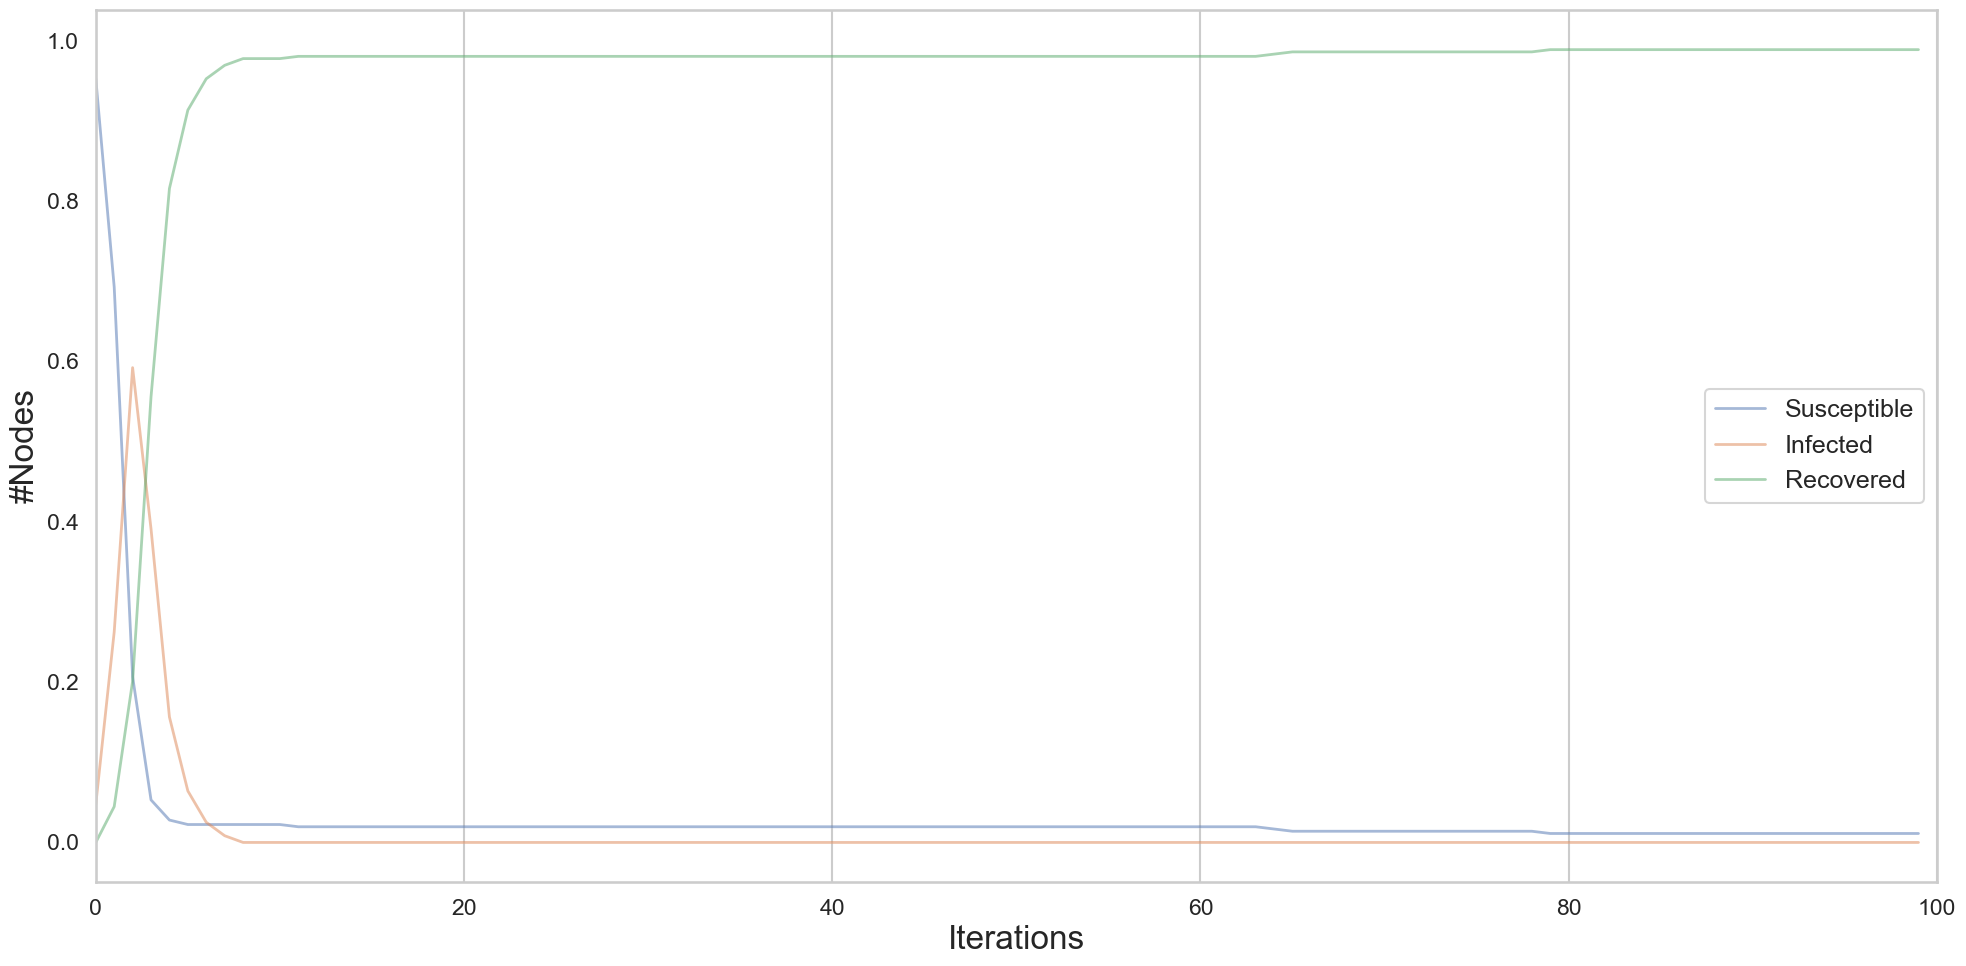

In [18]:
#second baseline: randomly assign vacc (no test/test accuracy 0) according to sf strat
#so per timestep pick random node, vacc random neighbor, iterate until budget per timestep is gone etc


vacc_number = 5 # vaccinations per timestep

# Identify isolated nodes
isolated_nodes = set(nx.isolates(G))

# Create a copy of the graph for simulation
G_sim = G.copy()

# Remove isolated nodes only from the simulation graph
G_sim.remove_nodes_from(isolated_nodes)

# Create the model on the simulation graph
model = gc.CompositeModel(G_sim)

# Define statuses
model.add_status("Susceptible")
model.add_status("Infected")
model.add_status("Recovered")

# Original infection and recovery rules
c1 = es.EdgeStochastic(beta, triggering_status="Infected")
model.add_rule("Susceptible", "Infected", c1)

c2 = ns.NodeStochastic(gamma)
model.add_rule("Infected", "Recovered", c2)

# Infect exactly 5 non-isolated nodes
infected_nodes = random.sample(list(G_sim.nodes()), 5)

config = mc.Configuration()

for node in G_sim.nodes():
    config.add_node_configuration(
        "status", node,
        1 if node in infected_nodes else 0
    )

model.set_initial_status(config)


import random

iterations = []

for t in range(100):
    # Run one SIR timestep
    iteration = model.iteration()
    iterations.append(iteration)

    # Randomly select 5 source nodes
    selected_nodes = random.sample(
        list(G_sim.nodes()),
        min(vacc_number, G_sim.number_of_nodes())
    )

    # Follow one random edge from each selected node
    for node in selected_nodes:
        neighbors = list(G_sim.neighbors(node))

        # Skip nodes without edges
        if not neighbors:
            continue

        target = random.choice(neighbors)

        # Apply intervention to the target node
        if model.status[target] == 0:  # Susceptible
            model.status[target] = 2  # Recovered

# Extract trends
trends = model.build_trends(iterations)
print(trends)


print("Original total nodes:", G.number_of_nodes())
print("Isolated nodes (excluded from simulation):", len(isolated_nodes))
print("Simulation nodes:", G_sim.number_of_nodes())
print("Initially infected nodes:", infected_nodes)
print(trends)
#plot SIR dynamics
%matplotlib inline

from ndlib.viz.mpl.DiffusionTrend import DiffusionTrend

viz = DiffusionTrend(model, trends)
viz.plot()
###to do: iterate this 10 times
###to do:iterate for different numbers of vaccines per timestep


c:\Users\anton\anaconda3\Lib\site-packages\ndlib\models\DiffusionModel.py:173: UserWarning: Initial infection missing: a random sample of 5% of graph nodes will be set as infected
  warnings.warn(


Timestep 1: 5 nodes changed from S to R
Timestep 2: 5 nodes changed from S to R
Timestep 3: 5 nodes changed from S to R
Timestep 4: 5 nodes changed from S to R
Timestep 5: 5 nodes changed from S to R
Timestep 6: 4 nodes changed from S to R
Timestep 7: 0 nodes changed from S to R
Timestep 8: 0 nodes changed from S to R
Timestep 9: 0 nodes changed from S to R
Timestep 10: 0 nodes changed from S to R
Timestep 11: 0 nodes changed from S to R
Timestep 12: 0 nodes changed from S to R
Timestep 13: 0 nodes changed from S to R
Timestep 14: 0 nodes changed from S to R
Timestep 15: 0 nodes changed from S to R
Timestep 16: 0 nodes changed from S to R
Timestep 17: 0 nodes changed from S to R
Timestep 18: 0 nodes changed from S to R
Timestep 19: 0 nodes changed from S to R
Timestep 20: 0 nodes changed from S to R
Timestep 21: 0 nodes changed from S to R
Timestep 22: 0 nodes changed from S to R
Timestep 23: 0 nodes changed from S to R
Timestep 24: 0 nodes changed from S to R
Timestep 25: 0 nodes chan

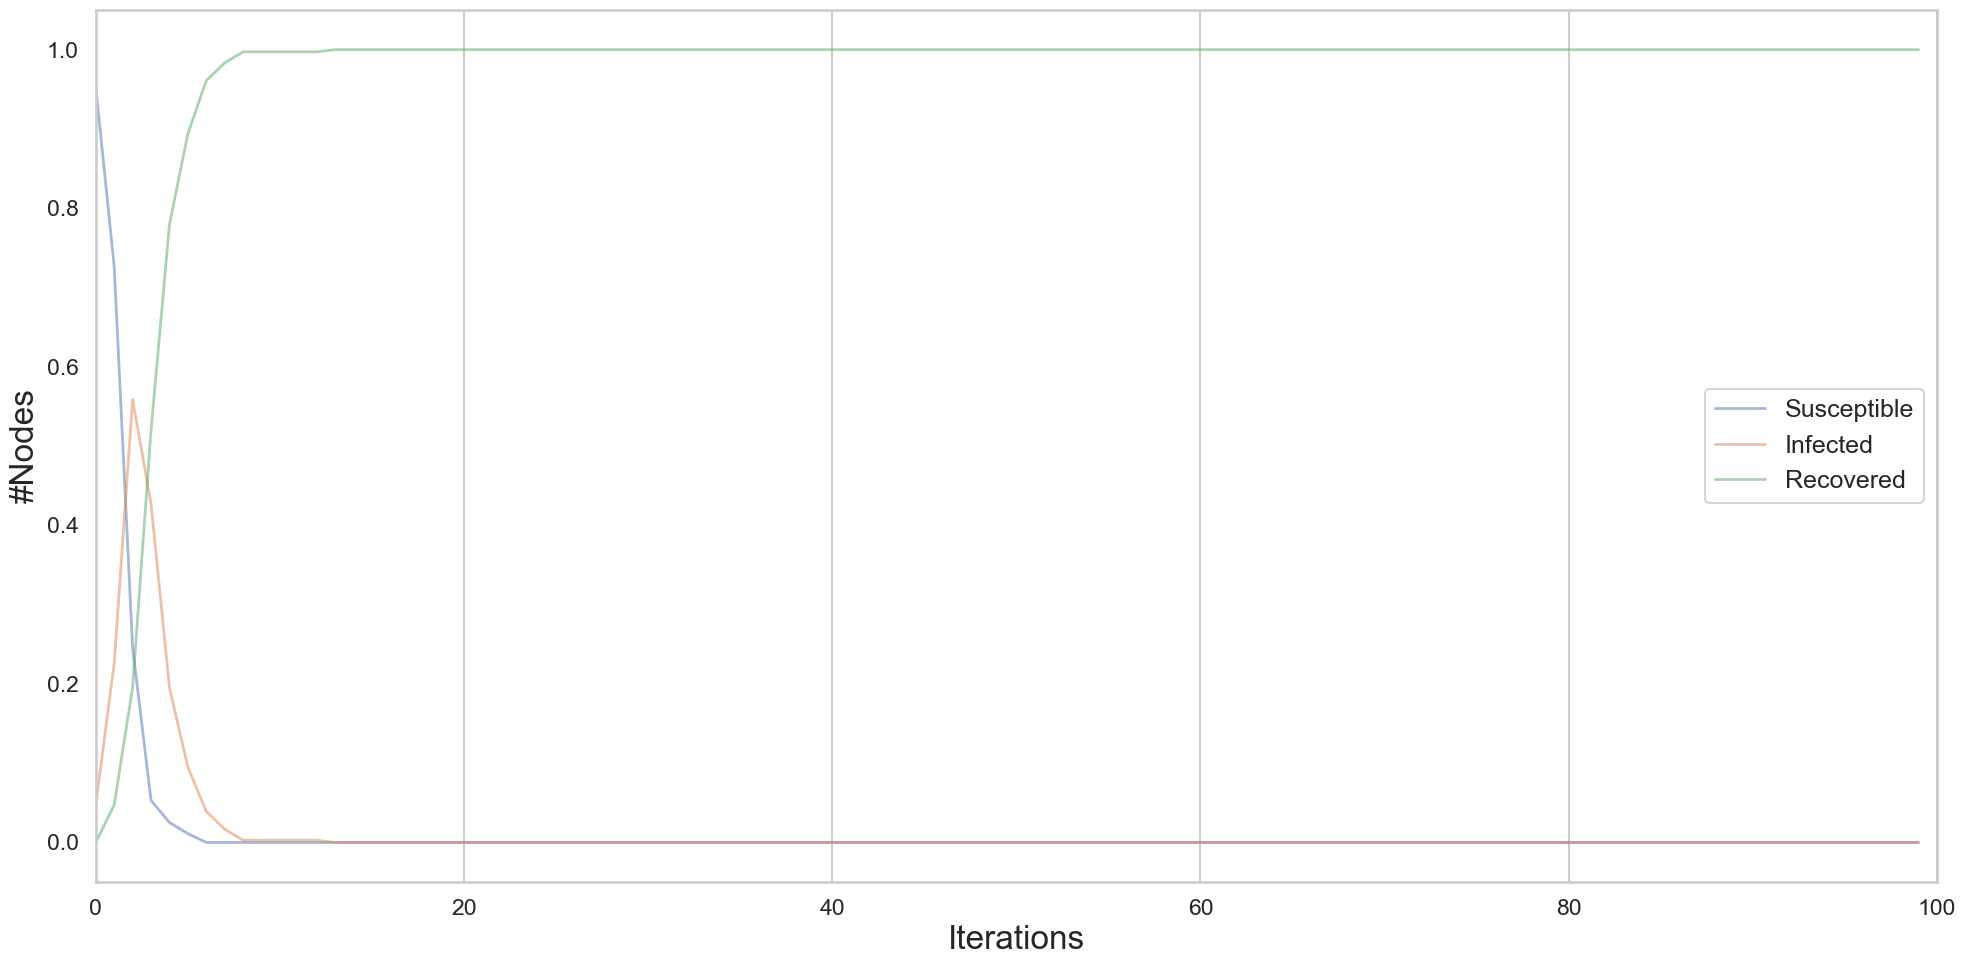

In [21]:
#how do we implement testing in network?
#accuracy 1: randomly pick k, test, then take those that have status s -> vacc

vacc_number = 5 # vaccinations per timestep

# Identify isolated nodes
isolated_nodes = set(nx.isolates(G))

# Create a copy of the graph for simulation
G_sim = G.copy()

# Remove isolated nodes only from the simulation graph
G_sim.remove_nodes_from(isolated_nodes)

# Create the model on the simulation graph
model = gc.CompositeModel(G_sim)

# Define statuses
model.add_status("Susceptible")
model.add_status("Infected")
model.add_status("Recovered")

# Original infection and recovery rules
c1 = es.EdgeStochastic(beta, triggering_status="Infected")
model.add_rule("Susceptible", "Infected", c1)

c2 = ns.NodeStochastic(gamma)
model.add_rule("Infected", "Recovered", c2)

# Infect exactly 5 non-isolated nodes
infected_nodes = random.sample(list(G_sim.nodes()), 5)

config = mc.Configuration()

for node in G_sim.nodes():
    config.add_node_configuration(
        "status", node,
        1 if node in infected_nodes else 0
    )

model.set_initial_status(config)


iterations = []

for t in range(100):
    # Run one SIR timestep
    iteration = model.iteration()
    iterations.append(iteration)

    successful_interventions = 0

    # Continue until 5 susceptible neighbors have been recovered
    while successful_interventions < vacc_number:

        # Randomly select a source node
        source = random.choice(list(G_sim.nodes()))

        # Find its neighbors
        neighbors = list(G_sim.neighbors(source))

        # Skip isolated source nodes
        if not neighbors:
            continue

        # Randomly select one neighbor
        target = random.choice(neighbors)

        # Apply intervention only if the neighbor is susceptible
        if model.status[target] == 0:  # Susceptible
            model.status[target] = 2  # Recovered
            successful_interventions += 1

        # Stop if no susceptible nodes remain
        if not any(
            model.status[node] == 0
            for node in G_sim.nodes()
        ):
            break

    print(
        f"Timestep {t + 1}: "
        f"{successful_interventions} nodes changed from S to R"
    )

# Extract trends
trends = model.build_trends(iterations)
print(trends)



print("Original total nodes:", G.number_of_nodes())
print("Isolated nodes (excluded from simulation):", len(isolated_nodes))
print("Simulation nodes:", G_sim.number_of_nodes())
print("Initially infected nodes:", infected_nodes)
print(trends)
#plot SIR dynamics
%matplotlib inline

from ndlib.viz.mpl.DiffusionTrend import DiffusionTrend

viz = DiffusionTrend(model, trends)
viz.plot()
###to do: iterate this 10 times
###to do:iterate for different numbers of vaccines per timestep


c:\Users\anton\anaconda3\Lib\site-packages\ndlib\models\DiffusionModel.py:173: UserWarning: Initial infection missing: a random sample of 5% of graph nodes will be set as infected
  warnings.warn(


Timestep 1: 5 successful interventions after 5 attempts
Timestep 2: 5 successful interventions after 6 attempts
Timestep 3: 5 successful interventions after 10 attempts
Timestep 4: 5 successful interventions after 15 attempts
Timestep 5: 5 successful interventions after 16 attempts
Timestep 6: 5 successful interventions after 7 attempts
Timestep 7: 5 successful interventions after 14 attempts
Timestep 8: 5 successful interventions after 7 attempts
Timestep 9: 5 successful interventions after 8 attempts
Timestep 10: 5 successful interventions after 9 attempts
Timestep 11: 5 successful interventions after 6 attempts
Timestep 12: 5 successful interventions after 10 attempts
Timestep 13: 5 successful interventions after 12 attempts
Timestep 14: 5 successful interventions after 19 attempts
Timestep 15: 5 successful interventions after 11 attempts
Timestep 16: 5 successful interventions after 8 attempts
Timestep 17: 5 successful interventions after 7 attempts
Timestep 18: 5 successful interv

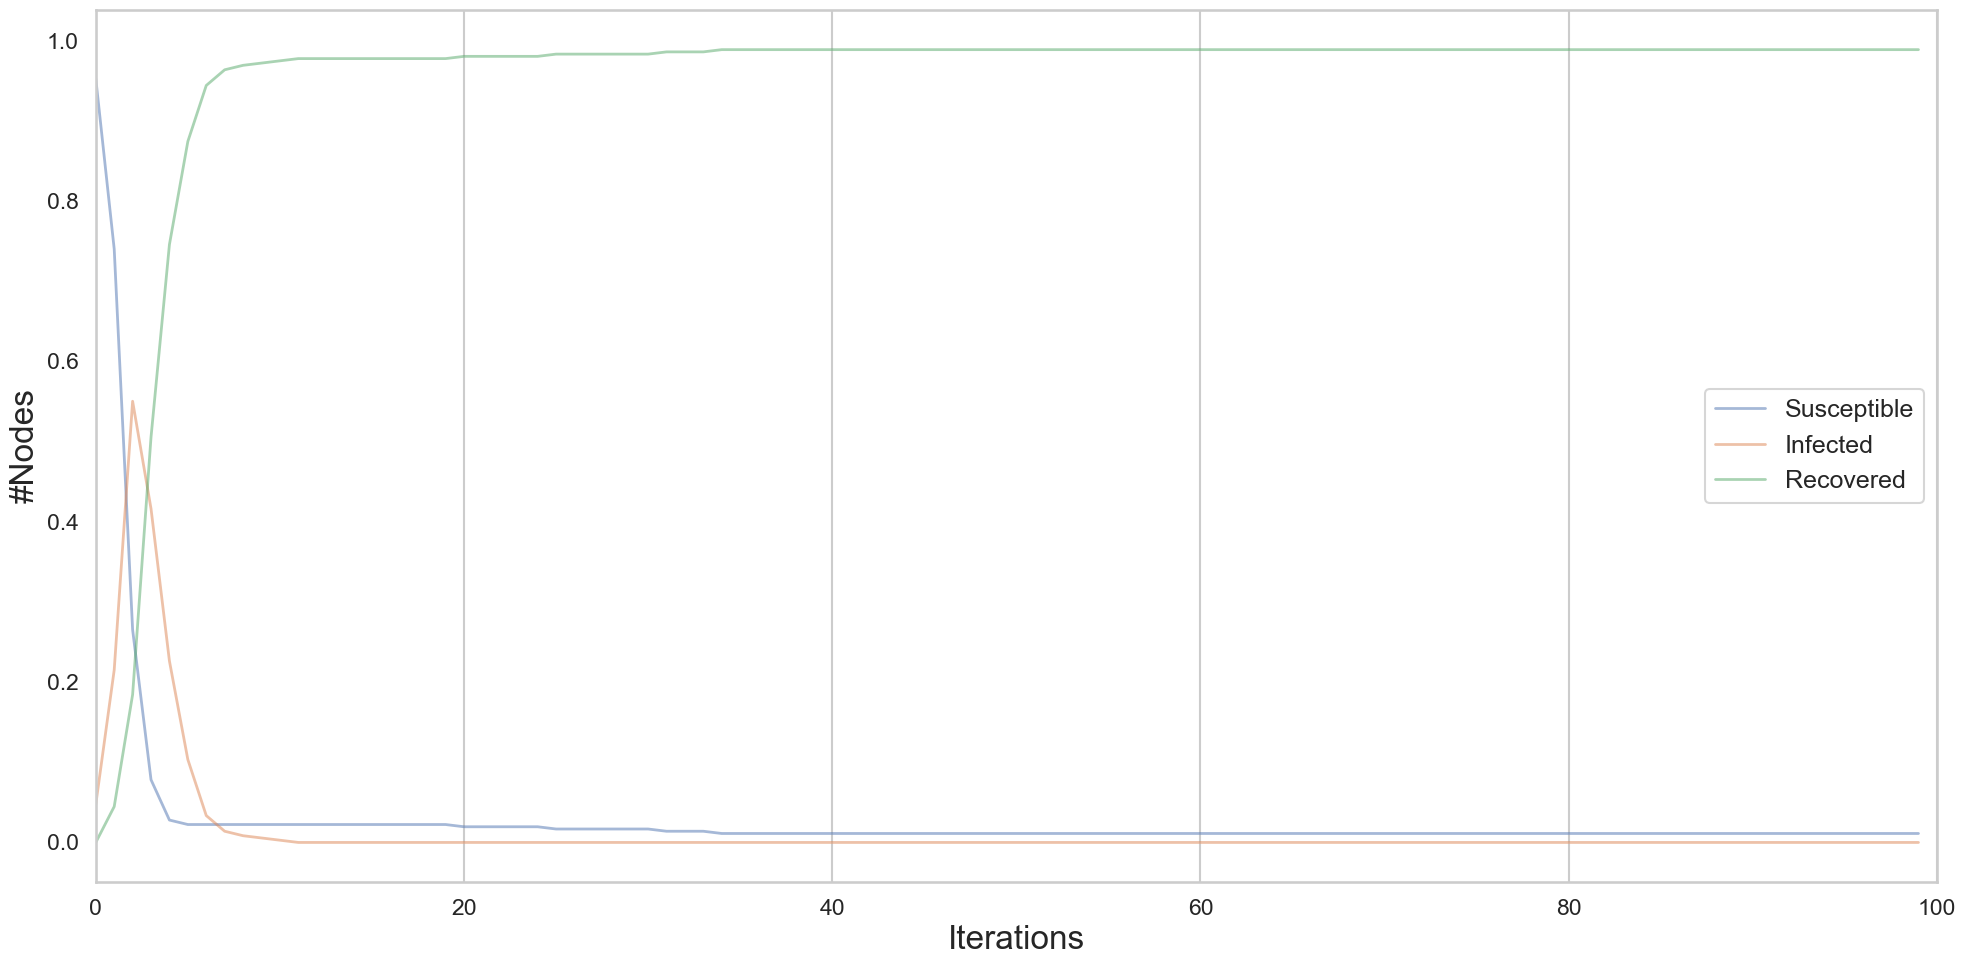

In [22]:
#stochastic: randomly pick k, test, with probability p= 0.75 or 0.5 pick those that have status s -> vacc    

vacc_number = 5 # vaccinations per timestep
p=0.5 ### to do: iterate for 0.75

# Identify isolated nodes
isolated_nodes = set(nx.isolates(G))

# Create a copy of the graph for simulation
G_sim = G.copy()

# Remove isolated nodes only from the simulation graph
G_sim.remove_nodes_from(isolated_nodes)

# Create the model on the simulation graph
model = gc.CompositeModel(G_sim)

# Define statuses
model.add_status("Susceptible")
model.add_status("Infected")
model.add_status("Recovered")

# Original infection and recovery rules
c1 = es.EdgeStochastic(beta, triggering_status="Infected")
model.add_rule("Susceptible", "Infected", c1)

c2 = ns.NodeStochastic(gamma)
model.add_rule("Infected", "Recovered", c2)

# Infect exactly 5 non-isolated nodes
infected_nodes = random.sample(list(G_sim.nodes()), 5)

config = mc.Configuration()

for node in G_sim.nodes():
    config.add_node_configuration(
        "status", node,
        1 if node in infected_nodes else 0
    )

model.set_initial_status(config)


iterations = []

for t in range(100):
    # Run one SIR timestep
    iteration = model.iteration()
    iterations.append(iteration)

    successful_interventions = 0
    attempts = 0
    max_attempts = 1000

    while successful_interventions < vacc_number and attempts < max_attempts:
        attempts += 1

        # Pick a random source node
        source = random.choice(list(G_sim.nodes()))

        # Pick one random neighbor
        neighbors = list(G_sim.neighbors(source))

        if not neighbors:
            continue

        target = random.choice(neighbors)

        # Draw a random number
        r = random.random()

        if r < p:
            # Stochastic skip branch
            if model.status[target] == 0:  # Susceptible
                model.status[target] = 2  # Recovered

            # Count this intervention regardless of target status
            successful_interventions += 1

        else:
            # Alternative branch
            if model.status[target] == 0:  # Susceptible
                model.status[target] = 2  # Recovered
                successful_interventions += 1
            # If target is not susceptible, try again without counting

    print(
        f"Timestep {t + 1}: "
        f"{successful_interventions} successful interventions "
        f"after {attempts} attempts"
    )

# Extract trends
trends = model.build_trends(iterations)
print(trends)




print("Original total nodes:", G.number_of_nodes())
print("Isolated nodes (excluded from simulation):", len(isolated_nodes))
print("Simulation nodes:", G_sim.number_of_nodes())
print("Initially infected nodes:", infected_nodes)
print(trends)
#plot SIR dynamics
%matplotlib inline

from ndlib.viz.mpl.DiffusionTrend import DiffusionTrend

viz = DiffusionTrend(model, trends)
viz.plot()
###to do: iterate this 10 times
###to do:iterate for different numbers of vaccines per timestep

